# NMF with multiple seeds

Run all cells from the repository root or `MF`. Choose the settings below,
check the solver statuses, then compare the figures. Each worker runs all
methods on the same data and starting point for one seed.

Install in the notebook's Python environment if needed:
```python
%pip install numpy scipy matplotlib pandas "joblib>=1.3,<2" threadpoolctl galahad-optrove==5.5.3
```

For `U` of shape `(m, r)` and `V` of shape `(r, n)`, minimize
$$F(U,V)=\tfrac12\|UV-M_{\mathrm{obs}}\|_F^2
 +\tfrac\alpha2(\|U\|_F^2+\|V\|_F^2)
 +\tfrac\beta2(\|(-U)_+\|_F^2+\|(-V)_+\|_F^2).$$
Negative entries are penalized. The data are uniform random factors plus
Gaussian noise; the starting factors are Gaussian.

Reference: [arXiv:2602.08069v1](https://arxiv.org/abs/2602.08069v1),
Section 5.2 / Appendix E.2, Algorithm 1 and subproblem (2). The paper's objective
is equation (28); this notebook uses the weights above. Current settings and
supplementary comparisons differ from the paper, so this is not an exact figure reproduction.

| Paper figure | History quantity |
| --- | --- |
| 3: nonnegativity violation | `penalty` |
| 4: gradient norm | `grad_norm` |
| 6: objective residual | `func` minus the plotting reference |

All plot sections are retained: common-iteration means, exact/Gauss-Newton
comparisons, medians, a representative seed, and the final arithmetic mean.
Their aggregation rules are described beside each figure.

All two-panel comparisons call `utils_new.plot_figures` directly.
`prepare_mean_histories` only computes the means and display cutoffs.


In [31]:
import sys
from pathlib import Path
from datetime import datetime

sys.dont_write_bytecode = True
MF_DIR = Path.cwd()
if not (MF_DIR / "oracles_mat_fac.py").exists():
    MF_DIR = MF_DIR / "MF"
sys.path.insert(0, str(MF_DIR.resolve()))

%reload_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
from utils_new import plot_figures

from joblib import cpu_count
from joblib.externals.loky import ProcessPoolExecutor
from concurrent.futures import wait, FIRST_COMPLETED
from IPython.display import HTML, display
from time import perf_counter
import heapq
import html
import importlib.metadata
import platform

%matplotlib inline

# Shared colors from the original multiple-seed figures.
method_colors = {
    "Gradient Method": "#E8601C", "LeAP-SSN": "black",
    "GLAd-SSN, p=0.2": "#9B8AC4", "GLAd-SSN, p=0.4": "#88A5DD",
    "GLAd-SSN, p=0.5": "#8DCBE4", "GLAd-SSN, p=0.6": "#C2E3D2",
    "GLAd-SSN, p=0.8": "#DDECBF", "Cubic Newton (GLRT)": "#A97900",
}

## Settings

- `seeds_to_try`: data and initialization seeds, shared by every method.
- `m, n, r`, `noise`, `alpha, beta`: dimensions, noise and objective weights.
- `initial_factor_std`: Gaussian starting-factor scale.
- `gradient_iterations`, `number_of_iterations`: gradient/Newton update budgets.
- `grad_tol`: absolute gradient-norm stopping tolerance; `None` disables it.
- `initial_lambda`: initial LeAP/GLAd shift; GLAd scales it with `||g||**p`.
- `lss_*`: inexact linear solve; `gn_exponents`: additional Gauss-Newton variants.
- `cubic_*`: [GLRT cubic baseline](CUBIC_SUBPROBLEM.md), independent of `initial_lambda`.

Every method checks `grad_tol` initially and after accepted updates. `success`
means the gradient target was reached; `iterations_exceeded` means the budget
ran out. Other exits retain their failure status. There is no objective stopping test.
LeAP/GLAd use fresh generalized Hessians; GN variants use approximate curvature.
Cubic uses inexact GLRT solves and accepts `f(x+s) <= f(x)+model_change`, with
cubic term `H_k * ||s||**3 / 6`; rejection doubles `H_k`, acceptance halves it
with floor `1e-5`.

`N_JOBS` is capped by available CPUs and seed count; `THREADS_PER_WORKER`
limits numerical-library threads. Use `N_JOBS=1` for sequential runs.
`plot_threshold` changes the first six plots only. `SAVE_FIGURES=True` exports
those plots and the representative/final-mean figures under `parallel_results/`.

Quick check: `(m, n, r) = (6, 4, 2)`, seeds `[549, 498]`, 20 gradient updates
and 5 Newton updates. These are check settings, not the full experiment.

In [32]:
# Original recorded seeds (uncomment for the 20-seed experiment):
# seeds_to_try = [549, 498, 483, 33, 528, 989, 465, 344, 153, 867,
#                 107, 424, 998, 230, 996, 229, 725, 911, 418, 146]
seeds_to_try = [549, 498, 483, 33, 528, 989]

# Data and objective
m, n, r = 50, 25, 4

noise = 0.2
alpha, beta = 0.01, 500.0
initial_factor_std = 0.05

# Iteration budgets and regularization
gradient_iterations = 8000
number_of_iterations = 2000
grad_tol = 1e-8  # Absolute outer gradient norm; None disables this tolerance.
initial_lambda = 10.0
lss_method = "minres"  # SciPy MINRES; GLRT keeps its compiled GALAHAD backend.
lss_tol = 1e-7
lss_maxiters = 800
gn_exponents = [0.2, 0.5]       # Additional exact/Gauss-Newton comparisons

# Additional nonconvex cubic baseline (independent of initial_lambda)
cubic_initial_H = 10.0
cubic_subproblem_tol = 1e-7  # Model-gradient residual relative to ||g||
cubic_glrt_max_iter = 6000  # Per-trial cap.
cubic_max_backtracks = 120

# Plotting and optional export
plot_threshold = 1e-8
SAVE_FIGURES = False

print("Trying seeds:", seeds_to_try)

# Parallel execution: choose multiple seeds above to use multiple workers.
N_JOBS = 6  # 1 for sequential execution.
THREADS_PER_WORKER = 1
PROGRESS_INTERVAL = 2.0

Trying seeds: [549, 498, 483, 33, 528, 989]


## Run one seed

Each worker returns histories, exit statuses, cubic work counts and timings.
Random draws and method order are fixed. Python exceptions identify the failed
seed and method; solver failures retain their last accepted history.

In [33]:
def run_one_seed(seed, settings, mf_directory, threads=1):
    """Run one independent seed with the original data draws and method order.

    m, n, r specify M:(m,n), U:(m,r), V:(r,n); packed iterates have (m+n)*r
    entries. Return plotting histories, cubic work statistics, exit statuses,
    method wall times, and the actual worker thread-pool configuration.
    """
    # Import inside the worker; only the seed/configuration cross processes.
    import contextlib
    import io
    import os
    import sys
    from time import perf_counter
    sys.dont_write_bytecode = True
    if mf_directory not in sys.path:
        sys.path.insert(0, mf_directory)
    import numpy as np
    from threadpoolctl import threadpool_limits, threadpool_info
    from methods import gradient_method, mf_gladssn, mf_leapssn, cubic_newton_nonconvex_new
    from oracles_mat_fac import PositiveMatrixFactorization
    from galahad import glrt  # Load native libraries before limiting threads.

    seed_started = perf_counter()
    with threadpool_limits(limits=threads):
        m = settings['m']
        n = settings['n']
        r = settings['r']
        noise = settings['noise']
        alpha = settings['alpha']
        beta = settings['beta']
        initial_factor_std = settings['initial_factor_std']
        gradient_iterations = settings['gradient_iterations']
        number_of_iterations = settings['number_of_iterations']
        grad_tol = settings['grad_tol']
        initial_lambda = settings['initial_lambda']
        lss_method = settings['lss_method']
        lss_tol = settings['lss_tol']
        lss_maxiters = settings['lss_maxiters']
        gn_exponents = settings['gn_exponents']
        cubic_initial_H = settings['cubic_initial_H']
        cubic_subproblem_tol = settings['cubic_subproblem_tol']
        cubic_glrt_max_iter = settings['cubic_glrt_max_iter']
        cubic_max_backtracks = settings['cubic_max_backtracks']

        rng = np.random.RandomState(seed)  # Same MT19937 sequence as np.random.seed(seed).

        # Ground truth
        U_true = rng.rand(m, r)
        V_true = rng.rand(n, r).T  # (r, n); preserve the previous random draw
        M_clean = U_true @ V_true

        # Noisy observed matrix
        M_obs = M_clean + noise * rng.randn(m, n)

        # Gaussian starting factors, shared by every method for this seed.
        # Keep the original draw order while storing V with shape (r, n).
        initial_values = initial_factor_std * rng.randn(m * r + n * r)
        U_0 = initial_values[:m*r].reshape(m, r)
        V_0 = initial_values[m*r:].reshape(n, r).T

        oracle = PositiveMatrixFactorization(M_obs, r=r, alpha=alpha, beta=beta)
        x_0 = oracle.pack(U_0, V_0)

        newton_options = dict(
            n_iters=number_of_iterations, grad_tol=grad_tol, H_0=initial_lambda,
            warnings=False, lss_tol=lss_tol, lss_maxiters=lss_maxiters,
            lss_method=lss_method, use_gauss_newton=False,
        )
        methods_to_run = {
            "Gradient Method": (
                gradient_method, (oracle, x_0),
                dict(max_iter=gradient_iterations, grad_tol=grad_tol, warnings=False),
            ),
            "LeAP-SSN": (mf_leapssn, (oracle, x_0), dict(newton_options)),
        }
        for p in (0.2, 0.4, 0.5, 0.6, 0.8):
            methods_to_run[f"GLAd-SSN, p={p:g}"] = (
                mf_gladssn, (oracle, x_0), dict(newton_options, p=p),
            )

        methods_to_run["Cubic Newton (GLRT)"] = (
            cubic_newton_nonconvex_new, (oracle, x_0),
            dict(
                n_iters=number_of_iterations,
                grad_tol=grad_tol,
                H_0=cubic_initial_H,
                subproblem_tol=cubic_subproblem_tol,
                glrt_max_iter=cubic_glrt_max_iter,
                max_backtracks=cubic_max_backtracks,
                warnings=False,
            ),
        )

        # Add matching Gauss-Newton variants after the original methods.
        original_method_names = list(methods_to_run)
        gn_base_names = ["LeAP-SSN"] + [f"GLAd-SSN, p={p:g}" for p in gn_exponents]
        for method_name in gn_base_names:
            solver, args, options = methods_to_run[method_name]
            methods_to_run[f"{method_name} (GN)"] = (
                solver, args, dict(options, use_gauss_newton=True)
            )


        plot_keys = ("func", "time", "grad_norm", "penalty")
        seed_histories, statuses, method_seconds = {}, {}, {}
        cubic_diagnostics = {}
        for name, (solver, args, options) in methods_to_run.items():
            method_started = perf_counter()
            try:
                with contextlib.redirect_stdout(io.StringIO()):
                    _, status, history = solver(*args, **options)
            except Exception as error:
                raise RuntimeError(f"Seed {seed}, method {name!r} failed") from error
            method_seconds[name] = perf_counter() - method_started
            statuses[name] = status
            seed_histories[name] = {
                key: np.asarray(history[key]) for key in plot_keys
            }
            if name == "Cubic Newton (GLRT)":
                cubic_diagnostics = {
                    key: np.asarray(history[key])
                    for key in ("hess_vec_calls", "glrt_iterations", "glrt_status",
                                "subproblem_relative_residual", "subproblem_calls", "H_k")
                    if key in history
                }
            del history
        thread_pools = threadpool_info()
        return dict(
            seed=int(seed), histories=seed_histories, cubic=cubic_diagnostics,
            statuses=statuses, method_seconds=method_seconds,
            seed_seconds=perf_counter() - seed_started,
            original_method_names=original_method_names, thread_pools=thread_pools,
            pid=os.getpid(),
        )

## Run the batch

Progress includes elapsed time and a rough remaining-time estimate. Interrupting
stops unfinished workers and keeps completed results in memory. Plot only a
complete batch. Inspect the exit-status table before interpreting convergence.

Batch time includes startup and shutdown. Plotted times are per-method wall
times with shared CPU load, not isolated speed benchmarks. `run_metadata`
records settings, package versions, hardware and thread limits.

In [34]:
def format_duration(seconds):
    seconds = max(0, int(round(seconds)))
    hours, remainder = divmod(seconds, 3600)
    minutes, seconds = divmod(remainder, 60)
    return f"{hours:d}h {minutes:02d}m {seconds:02d}s"


def estimate_remaining(completed_seconds, active_ages, queued, workers):
    """Estimate remaining wall seconds by scheduling onto predicted free slots.

    Completed durations and active ages are measured from submission to receipt,
    in seconds. None means insufficient observations or an overdue active seed.
    """
    if not active_ages and queued == 0:
        return 0.0, "complete"
    if not completed_seconds:
        return None, "waiting for the first completed seed"
    mean_seconds = float(np.mean(completed_seconds))
    if any(age >= mean_seconds for age in active_ages):
        return None, "uncertain: an active seed exceeds the observed mean"
    loads = [mean_seconds - age for age in active_ages]
    loads.extend([0.0] * (workers - len(loads)))
    heapq.heapify(loads)
    for _ in range(queued):
        available = heapq.heappop(loads)
        heapq.heappush(loads, available + mean_seconds)
    return max(loads), f"rough estimate from {len(completed_seconds)} completed seed(s)"


def render_progress(completed, active, queued, total, elapsed, eta, note, state="running"):
    running = ", ".join(str(seed) for seed in active) or "none"
    remaining = format_duration(eta) if eta is not None else "estimating"
    return HTML(
        f"<progress value='{completed}' max='{total}' style='width:100%'></progress>"
        f"<p><b>{completed}/{total} seeds complete</b> | {html.escape(state)}"
        f"<br>Elapsed: <b>{format_duration(elapsed)}</b>"
        f" | Remaining: <b>{remaining}</b>"
        f"<br>{html.escape(note)}"
        f"<br>Running: {html.escape(running)} | Queued: {queued}</p>"
    )


In [35]:
batch_complete = False  # Invalidate any previous completed batch before validation.
# Validate before launching workers.
if grad_tol is not None and (
    isinstance(grad_tol, (bool, np.bool_))
    or not isinstance(grad_tol, (int, float, np.integer, np.floating))
    or not np.isfinite(grad_tol) or grad_tol < 0
):
    raise ValueError("grad_tol must be a finite nonnegative real scalar, or None.")
for label, value in (("N_JOBS", N_JOBS), ("THREADS_PER_WORKER", THREADS_PER_WORKER)):
    if isinstance(value, bool) or not isinstance(value, (int, np.integer)) or value < 1:
        raise ValueError(f"{label} must be a positive integer.")
if not np.isfinite(PROGRESS_INTERVAL) or PROGRESS_INTERVAL <= 0:
    raise ValueError("PROGRESS_INTERVAL must be finite and positive.")
if not seeds_to_try or len(set(seeds_to_try)) != len(seeds_to_try):
    raise ValueError("Provide a nonempty list of distinct seeds.")
if any(isinstance(seed, bool) or not isinstance(seed, (int, np.integer))
       or not 0 <= seed < 2**32 for seed in seeds_to_try):
    raise ValueError("Seeds must be integers in [0, 2**32).")
if THREADS_PER_WORKER > cpu_count():
    raise ValueError("THREADS_PER_WORKER exceeds the available CPU count.")

experiment_config = {
    'm': m,
    'n': n,
    'r': r,
    'noise': noise,
    'alpha': alpha,
    'beta': beta,
    'initial_factor_std': initial_factor_std,
    'gradient_iterations': gradient_iterations,
    'number_of_iterations': number_of_iterations,
    'grad_tol': grad_tol,
    'initial_lambda': initial_lambda,
    'lss_method': lss_method,
    'lss_tol': lss_tol,
    'lss_maxiters': lss_maxiters,
    'gn_exponents': gn_exponents,
    'cubic_initial_H': cubic_initial_H,
    'cubic_subproblem_tol': cubic_subproblem_tol,
    'cubic_glrt_max_iter': cubic_glrt_max_iter,
    'cubic_max_backtracks': cubic_max_backtracks,
}
experiment_config["gn_exponents"] = list(gn_exponents)
gn_base_names = ["LeAP-SSN"] + [f"GLAd-SSN, p={p:g}" for p in experiment_config["gn_exponents"]]

effective_workers = min(int(N_JOBS), len(seeds_to_try),
                        max(1, cpu_count() // int(THREADS_PER_WORKER)))
print(f"Using {effective_workers} process(es), {THREADS_PER_WORKER} numerical-library "
      f"thread(s) each; {cpu_count()} logical CPUs available.")
if len(seeds_to_try) == 1:
    print("Only one seed is selected. Enable the multi-seed list above for parallel work.")

plot_keys = ("func", "time", "grad_norm", "penalty")
all_seeds_histories = {}
all_seeds_cubic_diagnostics = {}
all_seeds_statuses = {}
all_seeds_timing = {}
original_method_names = None
run_metadata = {
    "started_at": datetime.now().astimezone().isoformat(),
    "python": platform.python_version(),
    "platform": platform.platform(),
    "processor": platform.processor(),
    "packages": {name: importlib.metadata.version(name)
                 for name in ("numpy", "scipy", "joblib", "threadpoolctl", "galahad-optrove")},
    "precision": "float64",
    "seeds": [int(seed) for seed in seeds_to_try],
    "configuration": dict(experiment_config),
    "requested_workers": int(N_JOBS),
    "effective_workers": effective_workers,
    "threads_per_worker": int(THREADS_PER_WORKER),
    "state": "running",
}
# These are applied before workers import NumPy/SciPy/GALAHAD. The worker also
# uses threadpoolctl, so supported native libraries are capped during solves.
worker_environment = {
    name: str(THREADS_PER_WORKER)
    for name in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS",
                 "BLIS_NUM_THREADS", "VECLIB_MAXIMUM_THREADS", "NUMEXPR_NUM_THREADS")
}
worker_environment["PYTHONDONTWRITEBYTECODE"] = "1"

batch_started = perf_counter()
completed_turnarounds = []
pending = {}
next_seed_index = 0
progress = display(render_progress(0, [], len(seeds_to_try), len(seeds_to_try),
                                  0, None, "starting workers"), display_id=True)
executor = None
try:
    executor = ProcessPoolExecutor(max_workers=effective_workers, env=worker_environment)
    while next_seed_index < len(seeds_to_try) or pending:
        # Bound submissions so active ages include startup, but no long queue wait.
        while next_seed_index < len(seeds_to_try) and len(pending) < effective_workers:
            seed = int(seeds_to_try[next_seed_index])
            submitted_at = perf_counter()
            future = executor.submit(run_one_seed, seed, experiment_config,
                                     str(MF_DIR.resolve()), int(THREADS_PER_WORKER))
            pending[future] = (seed, submitted_at)
            next_seed_index += 1

        finished, _ = wait(pending, timeout=PROGRESS_INTERVAL, return_when=FIRST_COMPLETED)
        errors = []
        for future in finished:
            seed, submitted_at = pending.pop(future)
            received_at = perf_counter()
            try:
                result = future.result()
            except Exception as error:
                errors.append((seed, error))
                continue
            turnaround = received_at - submitted_at
            completed_turnarounds.append(turnaround)
            all_seeds_histories[seed] = result["histories"]
            all_seeds_cubic_diagnostics[seed] = result["cubic"]
            all_seeds_statuses[seed] = result["statuses"]
            all_seeds_timing[seed] = {
                "turnaround_seconds": turnaround,
                "seed_seconds": result["seed_seconds"],
                "method_seconds": result["method_seconds"],
                "thread_pools": result["thread_pools"],
                "pid": result["pid"],
            }
            if original_method_names is None:
                original_method_names = result["original_method_names"]
            elif original_method_names != result["original_method_names"]:
                raise RuntimeError("Method order differs across seeds.")

        if errors:
            seed, error = errors[0]
            raise RuntimeError(
                f"Seed {seed} raised an exception. Completed results remain in "
                "all_seeds_histories; the batch will not be plotted as complete."
            ) from error

        now = perf_counter()
        queued = len(seeds_to_try) - next_seed_index
        ages = [now - submitted for _, submitted in pending.values()]
        eta, note = estimate_remaining(completed_turnarounds, ages, queued, effective_workers)
        progress.update(render_progress(
            len(all_seeds_histories), [seed for seed, _ in pending.values()],
            queued, len(seeds_to_try), now - batch_started, eta, note))

    batch_complete = True
    run_metadata["state"] = "complete"
except KeyboardInterrupt:
    run_metadata["state"] = "interrupted"
    raise
except BaseException:
    run_metadata["state"] = "failed"
    raise
finally:
    if executor is not None:
        # A stopped/failed cell terminates its processes instead of leaving
        # expensive seeds running in the background.
        executor.shutdown(wait=True, kill_workers=not batch_complete)
    batch_elapsed_seconds = perf_counter() - batch_started
    run_metadata["batch_elapsed_seconds"] = batch_elapsed_seconds
    run_metadata["completed_seeds"] = list(all_seeds_histories)
    progress.update(render_progress(
        len(all_seeds_histories), [], len(seeds_to_try) - len(all_seeds_histories),
        len(seeds_to_try), batch_elapsed_seconds, 0 if batch_complete else None,
        "all seed calculations returned" if batch_complete else
        "unfinished workers stopped; completed results remain in memory",
        run_metadata["state"]))

# Restore requested seed order so completion order cannot affect averaging/plots.
all_seeds_histories = {seed: all_seeds_histories[seed] for seed in seeds_to_try}
all_seeds_cubic_diagnostics = {seed: all_seeds_cubic_diagnostics[seed] for seed in seeds_to_try}
all_seeds_statuses = {seed: all_seeds_statuses[seed] for seed in seeds_to_try}
all_seeds_timing = {seed: all_seeds_timing[seed] for seed in seeds_to_try}
print("Batch wall time (startup through shutdown):", format_duration(batch_elapsed_seconds))
print("Outer gradient tolerance:", grad_tol)
print("iterations_exceeded means the iteration budget was reached, not verified convergence.")
status_rows = "".join(
    "<tr><td>" + str(seed) + "</td><td>" + html.escape(method) + "</td><td>"
    + html.escape(status) + "</td><td>"
    + f"{all_seeds_histories[seed][method]['grad_norm'][-1]:.3e}" + "</td><td>"
    + format_duration(all_seeds_timing[seed]["method_seconds"][method]) + "</td></tr>"
    for seed in seeds_to_try for method, status in all_seeds_statuses[seed].items()
)
display(HTML("<details><summary>Solver exit statuses and measured method times</summary>"
             "<table><tr><th>Seed</th><th>Method</th><th>Status</th><th>Final gradient norm</th><th>Wall time</th></tr>"
             + status_rows + "</table></details>"))
unusual_exits = [(seed, method, status) for seed, statuses in all_seeds_statuses.items()
                 for method, status in statuses.items()
                 if status != "iterations_exceeded"
                 and status != "success" and not status.startswith("success, ")]
if unusual_exits:
    print("Review these solver exits before interpreting the plots:")
    for seed, method, status in unusual_exits:
        print(f"  seed {seed}: {method}: {status}")


Using 6 process(es), 1 numerical-library thread(s) each; 16 logical CPUs available.


Batch wall time (startup through shutdown): 0h 00m 44s
Outer gradient tolerance: 1e-08
iterations_exceeded means the iteration budget was reached, not verified convergence.


Seed,Method,Status,Final gradient norm,Wall time
549,Gradient Method,iterations_exceeded,1.869e-02,0h 00m 02s
549,LeAP-SSN,"success, 129 iters",1.006e-09,0h 00m 01s
549,"GLAd-SSN, p=0.2","success, 261 iters",2.175e-09,0h 00m 02s
549,"GLAd-SSN, p=0.4","success, 218 iters",2.215e-09,0h 00m 02s
549,"GLAd-SSN, p=0.5","success, 208 iters",2.088e-09,0h 00m 02s
549,"GLAd-SSN, p=0.6","success, 148 iters",4.631e-10,0h 00m 01s
549,"GLAd-SSN, p=0.8","success, 231 iters",9.478e-10,0h 00m 02s
549,Cubic Newton (GLRT),"success, 68 iters",1.834e-09,0h 00m 01s
549,LeAP-SSN (GN),"numerical_stagnation, 831 iters",7.467e-08,0h 00m 08s
549,"GLAd-SSN, p=0.2 (GN)","numerical_stagnation, 856 iters",6.413e-08,0h 00m 12s


Review these solver exits before interpreting the plots:
  seed 549: LeAP-SSN (GN): numerical_stagnation, 831 iters
  seed 549: GLAd-SSN, p=0.2 (GN): numerical_stagnation, 856 iters
  seed 549: GLAd-SSN, p=0.5 (GN): numerical_stagnation, 895 iters
  seed 498: LeAP-SSN (GN): numerical_stagnation, 454 iters
  seed 498: GLAd-SSN, p=0.2 (GN): numerical_stagnation, 617 iters
  seed 498: GLAd-SSN, p=0.5 (GN): numerical_stagnation, 594 iters
  seed 483: LeAP-SSN (GN): numerical_stagnation, 424 iters
  seed 483: GLAd-SSN, p=0.2 (GN): numerical_stagnation, 765 iters
  seed 483: GLAd-SSN, p=0.5 (GN): numerical_stagnation, 789 iters
  seed 33: LeAP-SSN (GN): numerical_stagnation, 408 iters
  seed 33: GLAd-SSN, p=0.2 (GN): numerical_stagnation, 436 iters
  seed 33: GLAd-SSN, p=0.5 (GN): numerical_stagnation, 466 iters
  seed 528: LeAP-SSN (GN): numerical_stagnation, 332 iters
  seed 528: GLAd-SSN, p=0.2 (GN): numerical_stagnation, 427 iters
  seed 528: GLAd-SSN, p=0.5 (GN): numerical_stagnation, 4

## Means over common iterations

Every seed has equal weight. Each method ends at its shortest run. Runtime
plots pair the mean metric with mean time at the same iteration. This differs
from the final mean, which uses a shared runtime grid and retains stopped runs.

In [36]:
if not batch_complete or set(all_seeds_histories) != set(seeds_to_try):
    raise RuntimeError("Complete every requested seed before averaging.")
template_seed = seeds_to_try[0]
averaged_history = {
    method_name: {
        measure: np.zeros_like(history[measure], dtype=float)
        for measure in plot_keys
    }
    for method_name, history in all_seeds_histories[template_seed].items()
}

def add_common(a, b):
    """Add arrays only through the shorter run's last recorded iteration."""
    n = min(len(a), len(b))
    return a[:n] + b[:n]

for seed in seeds_to_try:
    for method_name, history in all_seeds_histories[seed].items():
        for measure in plot_keys:
            averaged_history[method_name][measure] = add_common(
                averaged_history[method_name][measure], history[measure]
            )

for method_name in averaged_history:
    for measure in plot_keys:
        averaged_history[method_name][measure] /= len(seeds_to_try)
    print(method_name, ": averaging all seeds through iteration",
          len(averaged_history[method_name]["func"]) - 1)

Gradient Method : averaging all seeds through iteration 8000
LeAP-SSN : averaging all seeds through iteration 129
GLAd-SSN, p=0.2 : averaging all seeds through iteration 171
GLAd-SSN, p=0.4 : averaging all seeds through iteration 196
GLAd-SSN, p=0.5 : averaging all seeds through iteration 166
GLAd-SSN, p=0.6 : averaging all seeds through iteration 148
GLAd-SSN, p=0.8 : averaging all seeds through iteration 167
Cubic Newton (GLRT) : averaging all seeds through iteration 52
LeAP-SSN (GN) : averaging all seeds through iteration 332
GLAd-SSN, p=0.2 (GN) : averaging all seeds through iteration 427
GLAd-SSN, p=0.5 (GN) : averaging all seeds through iteration 421


## Objective, gradient and penalty

The objective reference is the best observed mean among these methods, not a
known optimum. `plot_threshold` trims objective and gradient curves. Penalty
plots retain zeros and later rebounds, with a linear scale near zero.

In [37]:
histories = {name: averaged_history[name] for name in original_method_names}
line_widths = [2.0] * len(histories)
line_styles = ["-"] * len(histories)
colors = [method_colors[name] for name in histories]
mn_func = min(np.min(history["func"]) for history in histories.values())
figures = {}

Last Mean objective - best observed mean of Gradient Method: 0.016068149959806988
Last Mean objective - best observed mean of LeAP-SSN: 0.020258846785193185
Last Mean objective - best observed mean of GLAd-SSN, p=0.2: 0.012855605943737913
Last Mean objective - best observed mean of GLAd-SSN, p=0.4: 0.0
Last Mean objective - best observed mean of GLAd-SSN, p=0.5: 0.007157730543834617
Last Mean objective - best observed mean of GLAd-SSN, p=0.6: 0.025298710889526177
Last Mean objective - best observed mean of GLAd-SSN, p=0.8: 0.012201422898499459
Last Mean objective - best observed mean of Cubic Newton (GLRT): 0.016779063533153504


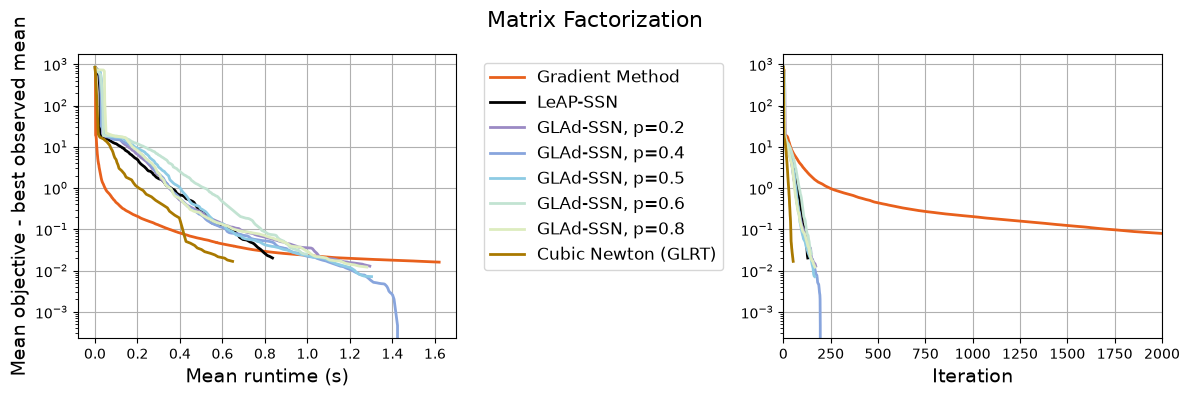

Last Mean gradient norm of Gradient Method: 0.017838031918597952
Last Mean gradient norm of LeAP-SSN: 0.03938894054973558
Last Mean gradient norm of GLAd-SSN, p=0.2: 0.013608185546324647
Last Mean gradient norm of GLAd-SSN, p=0.4: 0.013271200536756978
Last Mean gradient norm of GLAd-SSN, p=0.5: 0.018484774954393917
Last Mean gradient norm of GLAd-SSN, p=0.6: 0.043329752313103716
Last Mean gradient norm of GLAd-SSN, p=0.8: 0.007740908033196644
Last Mean gradient norm of Cubic Newton (GLRT): 0.10937580803511358


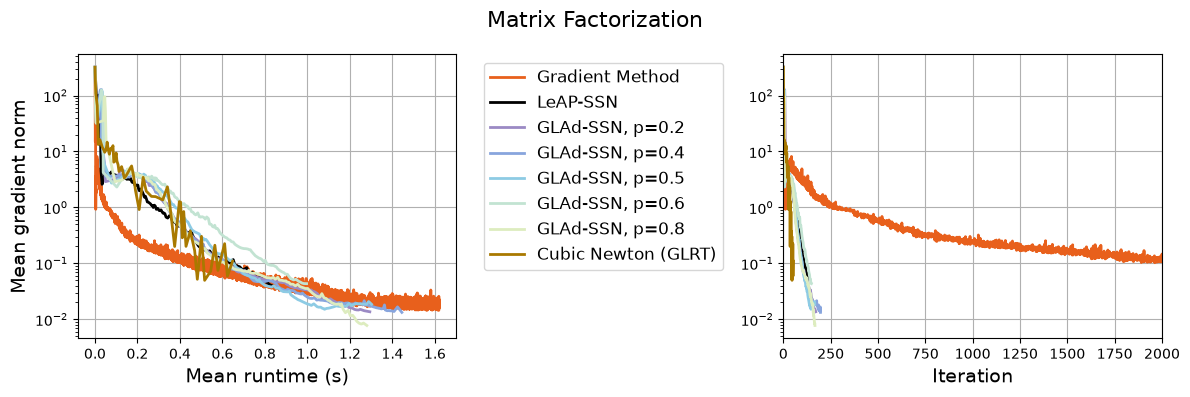

Last Mean penalty of Gradient Method: 0.0010027046245067968
Last Mean penalty of LeAP-SSN: 0.0009347193913061578
Last Mean penalty of GLAd-SSN, p=0.2: 0.001045316823074463
Last Mean penalty of GLAd-SSN, p=0.4: 0.0009002549247987057
Last Mean penalty of GLAd-SSN, p=0.5: 0.0008896009168199359
Last Mean penalty of GLAd-SSN, p=0.6: 0.0009804634788328878
Last Mean penalty of GLAd-SSN, p=0.8: 0.0010326062662225522
Last Mean penalty of Cubic Newton (GLRT): 0.001023147244391809


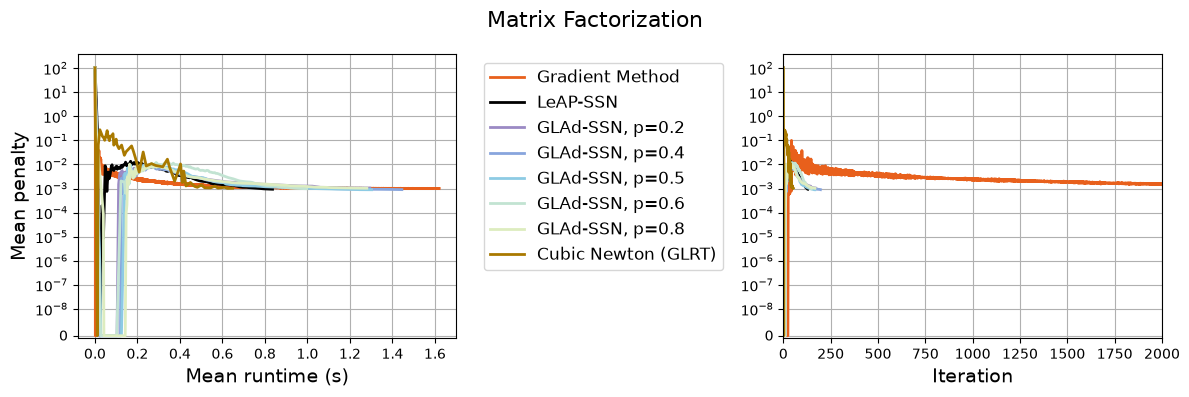

In [38]:
for measure, reference, ylabel in [
    ("func", mn_func, "Mean objective - best observed mean"),
    ("grad_norm", 0, "Mean gradient norm"),
    ("penalty", 0, "Mean penalty"),
]:
    fig = plot_figures(
        list(histories.values()), list(histories.keys()),
        colors=colors, linewidths=line_widths, linestyles=line_styles,
        n=n, m=m, mu_str=None, xlabel="Mean runtime (s)",
        f_star=reference, threshold=plot_threshold,
        suptitle="Matrix Factorization", max_iter=number_of_iterations,
        which_measure_1=measure, which_measure_2=measure, ylabel=ylabel,
    )
    figures[measure] = fig
    plt.show()
    plt.close(fig)

## Exact Hessian and Gauss-Newton

Matching methods share colors; dashed lines use GN curvature. Data and starts
are identical. This comparison uses its own best observed mean objective.

Last Mean objective - best observed mean of Gradient Method: 0.025151104378377198
Last Mean objective - best observed mean of Cubic Newton (GLRT): 0.025862017951723715
Last Mean objective - best observed mean of LeAP-SSN (exact): 0.029341801203763396
Last Mean objective - best observed mean of LeAP-SSN (GN): 0.0039640529349398435
Last Mean objective - best observed mean of GLAd-SSN, p=0.2 (exact): 0.021938560362308124
Last Mean objective - best observed mean of GLAd-SSN, p=0.2 (GN): 0.0021107629392673743
Last Mean objective - best observed mean of GLAd-SSN, p=0.5 (exact): 0.016240684962404828
Last Mean objective - best observed mean of GLAd-SSN, p=0.5 (GN): 0.0


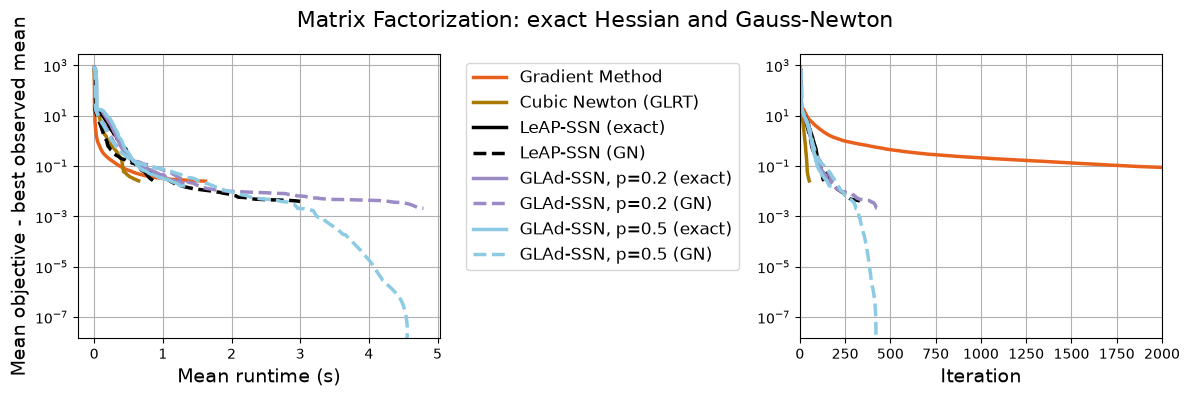

Last Mean gradient norm of Gradient Method: 0.017838031918597952
Last Mean gradient norm of Cubic Newton (GLRT): 0.10937580803511358
Last Mean gradient norm of LeAP-SSN (exact): 0.03938894054973558
Last Mean gradient norm of LeAP-SSN (GN): 0.002251705932689568
Last Mean gradient norm of GLAd-SSN, p=0.2 (exact): 0.013608185546324647
Last Mean gradient norm of GLAd-SSN, p=0.2 (GN): 0.0030181054850820076
Last Mean gradient norm of GLAd-SSN, p=0.5 (exact): 0.018484774954393917
Last Mean gradient norm of GLAd-SSN, p=0.5 (GN): 0.00013361577150834865


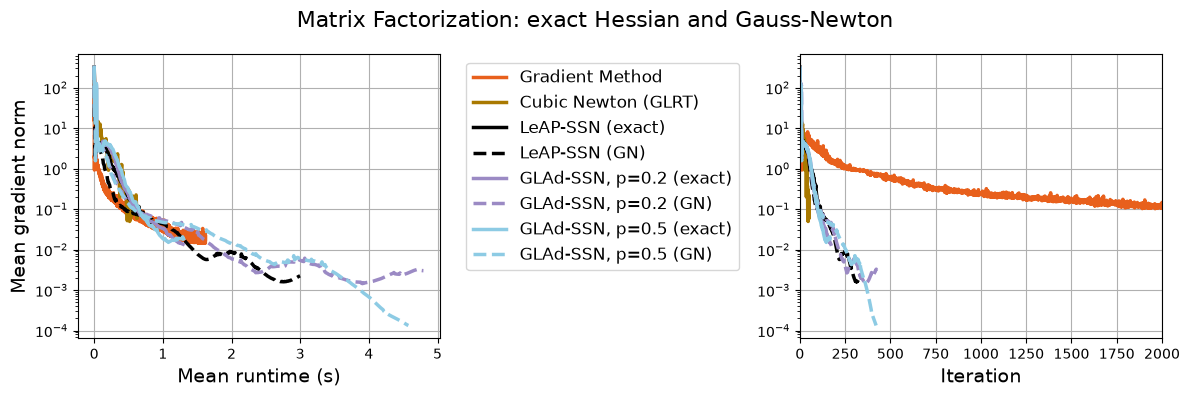

Last Mean penalty of Gradient Method: 0.0010027046245067968
Last Mean penalty of Cubic Newton (GLRT): 0.001023147244391809
Last Mean penalty of LeAP-SSN (exact): 0.0009347193913061578
Last Mean penalty of LeAP-SSN (GN): 0.0008585064413799065
Last Mean penalty of GLAd-SSN, p=0.2 (exact): 0.001045316823074463
Last Mean penalty of GLAd-SSN, p=0.2 (GN): 0.0008422749519185468
Last Mean penalty of GLAd-SSN, p=0.5 (exact): 0.0008896009168199359
Last Mean penalty of GLAd-SSN, p=0.5 (GN): 0.0008267259753942125


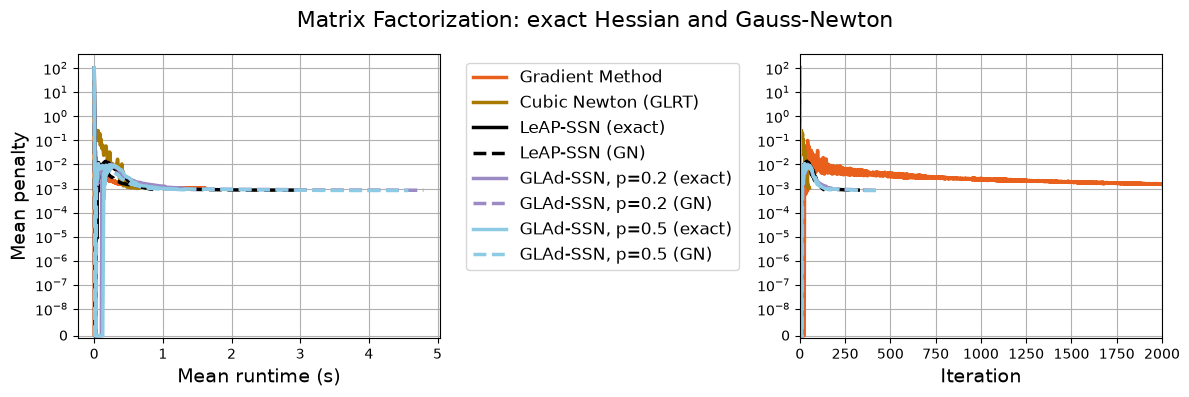

In [39]:
# Select matching exact/Gauss-Newton pairs without changing the original plots.
comparison_names = ["Gradient Method", "Cubic Newton (GLRT)"]
comparison_colors = [colors[0], colors[original_method_names.index("Cubic Newton (GLRT)")]]
comparison_styles = ["-", "-"]
for method_name in gn_base_names:
    color = colors[original_method_names.index(method_name)]
    comparison_names.extend([method_name, f"{method_name} (GN)"])
    comparison_colors.extend([color, color])
    comparison_styles.extend(["-", "--"])

comparison_histories = [averaged_history[name] for name in comparison_names]
comparison_labels = [
    name if name in ("Gradient Method", "Cubic Newton (GLRT)") or name.endswith(" (GN)") else f"{name} (exact)"
    for name in comparison_names
]
comparison_reference = min(np.min(history["func"]) for history in comparison_histories)

for measure, reference, ylabel in [
    ("func", comparison_reference, "Mean objective - best observed mean"),
    ("grad_norm", 0, "Mean gradient norm"),
    ("penalty", 0, "Mean penalty"),
]:
    fig = plot_figures(
        comparison_histories, comparison_labels,
        colors=comparison_colors, linewidths=[2.5] * len(comparison_names),
        linestyles=comparison_styles,
        n=n, m=m, mu_str=None, xlabel="Mean runtime (s)",
        f_star=reference, threshold=plot_threshold,
        suptitle="Matrix Factorization: exact Hessian and Gauss-Newton",
        max_iter=number_of_iterations,
        which_measure_1=measure, which_measure_2=measure, ylabel=ylabel,
    )
    figures[f"{measure}_gn"] = fig
    plt.show()
    plt.close(fig)


## Save the six mean figures

`SAVE_FIGURES=True` saves these PDFs in a new ignored `parallel_results/` folder.
Representative and final-mean plots have their own exports below.

In [40]:
if SAVE_FIGURES:
    output_dir = MF_DIR / "parallel_results" / datetime.now().strftime("%Y%m%d_%H%M%S_%f")
    output_dir.mkdir(parents=True, exist_ok=False)
    for measure, fig in figures.items():
        fig.savefig(output_dir / f"{measure}.pdf", bbox_inches="tight")
    print("Saved figures to", output_dir)

## Representative actual run

One shared seed is selected for every method and metric. It is the **medoid**
of first-hit iteration ranks at fixed gradient targets: unreached targets tie
last, method families and targets have equal weight, and the smallest seed
breaks ties. Runtime does not influence selection. This diagnostic rule does
not guarantee typical penalty behavior; it does not replace the all-seed means.
See [Kaufman and Rousseeuw (1987)](https://wis.kuleuven.be/stat/robust/papers/publications-1987/kaufmanrousseeuw-clusteringbymedoids-l1norm-1987.pdf).

Curves are actual recorded values, with no averaging or extension. Circles mark
endpoints; zeros remain visible. The objective reference is the best observed
value for this seed. The iteration view defaults to 150 updates; `None` shows
all updates. An explicit seed override is labelled an example.

The penalty can return above zero as factor entries change sign; only the total
objective is required to decrease. Its axis is linear below
`representative_penalty_zero_scale` (default `1e-5`), then logarithmic. All values
are retained; this scale is independent of the gradient/objective scale.


In [43]:
from representative_plots import (
    select_representative_seed, target_summary,
    plot_target_times,
)
import pandas as pd
import json

# Selection settings: one method per family; runtime does not affect selection.
representative_selection_methods = [
    "Gradient Method", "LeAP-SSN", "GLAd-SSN, p=0.5", "Cubic Newton (GLRT)",
]
representative_gradient_targets = [1e2, 1.0, 1e-2, 1e-4, 1e-6, 1e-8]
representative_plot_methods = list(original_method_names)
representative_seed_override = None  # An explicit seed is labelled "example".
comparison_gradient_target = 1e-6     # Reporting target, not the solver grad_tol.
representative_zero_scale = 1e-14
representative_penalty_zero_scale = 1e-5  # Linear near zero; keeps zero-to-positive rebounds.
representative_max_iter = 150          # Display zoom only; None shows the full run.
representative_max_time = None

if not batch_complete or set(all_seeds_histories) != set(seeds_to_try):
    raise RuntimeError("Complete the seed batch before selecting a representative run.")
representative_selection = select_representative_seed(
    all_seeds_histories, representative_selection_methods, representative_gradient_targets)
representative_seed = (representative_selection["seed"] if representative_seed_override is None
                       else int(representative_seed_override))
representative_label = "Representative" if representative_seed_override is None else "Example"
print(f"{representative_label} seed: {representative_seed}")
if representative_seed_override is None and len(representative_selection["tied_seeds"]) > 1:
    print("Tied medoids:", representative_selection["tied_seeds"], "-- using the smallest seed.")
if not representative_selection["informative"]:
    print("The milestone ranks do not distinguish these seeds; there is no unique typical run.")
selection_scores = pd.DataFrame([
    {"seed": seed, "medoid score": score, "shown": seed == representative_seed}
    for seed, score in representative_selection["scores"].items()
])
display(selection_scores.style.format({"medoid score": "{:.4f}"}))


Representative seed: 989


,seed,medoid score,shown
0,33,0.3500,False
1,483,0.3383,False
2,498,0.3017,False
3,528,0.3217,False
4,549,0.2950,False
5,989,0.2733,True


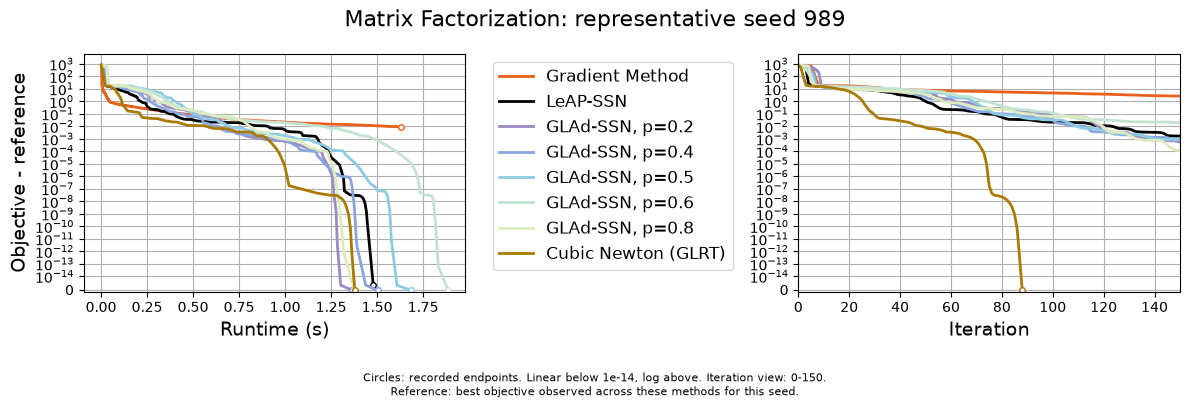

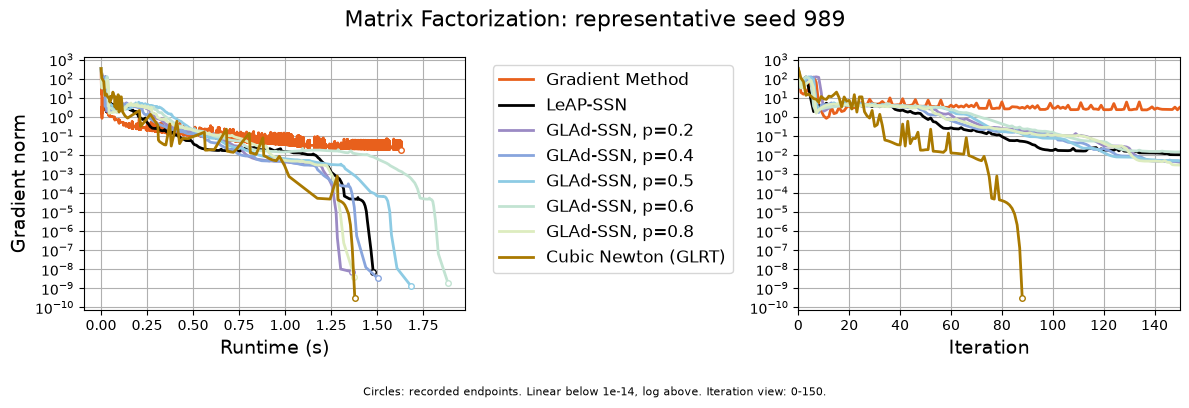

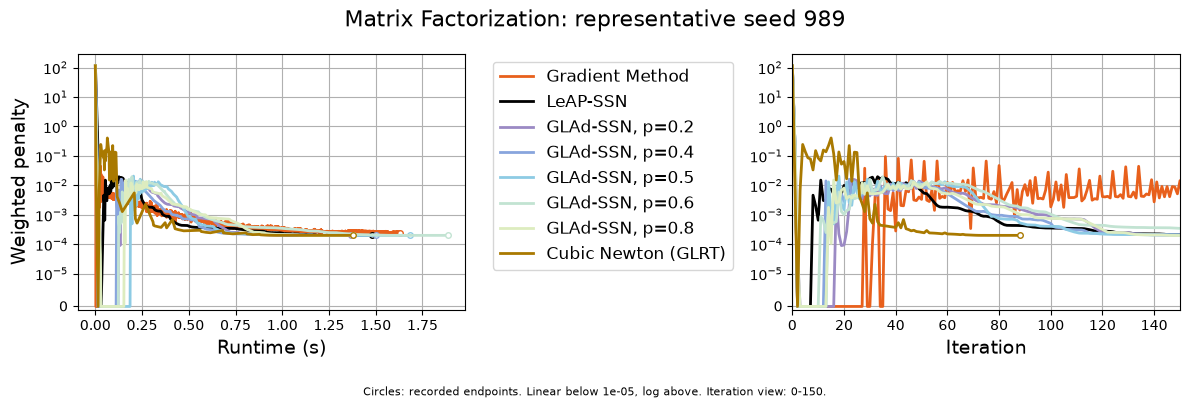

Reporting target: 1e-06; actual solver grad_tol: 1e-08


,method,reached,hit_iteration,hit_time,final_gradient,final_penalty,status
40,Gradient Method,False,--,--,1.901e-02,2.355e-04,iterations_exceeded
41,LeAP-SSN,True,188,1.45,6.788e-09,2.007e-04,"success, 190 iters"
42,"GLAd-SSN, p=0.2",True,178,1.28,7.199e-09,2.007e-04,"success, 180 iters"
43,"GLAd-SSN, p=0.4",True,194,1.39,3.413e-09,2.007e-04,"success, 196 iters"
44,"GLAd-SSN, p=0.5",True,189,1.58,1.383e-09,2.007e-04,"success, 191 iters"
45,"GLAd-SSN, p=0.6",True,245,1.83,1.845e-09,2.007e-04,"success, 246 iters"
46,"GLAd-SSN, p=0.8",True,166,1.32,4.108e-09,2.007e-04,"success, 167 iters"
47,Cubic Newton (GLRT),True,87,1.36,2.983e-10,2.007e-04,"success, 88 iters"


In [44]:
# Same colors as the mean figures; optional GN methods use matching dashed lines.
representative_base_colors = method_colors
representative_styles = {
    name: dict(color=representative_base_colors[name.removesuffix(" (GN)")],
               linestyle="--" if name.endswith(" (GN)") else "-")
    for name in representative_plot_methods
}
representative_histories = {
    name: all_seeds_histories[representative_seed][name] for name in representative_plot_methods
}
representative_reference = min(np.min(h["func"]) for h in representative_histories.values())
representative_figures = {}
for measure, reference, ylabel in [
    ("func", representative_reference, "Objective - reference"),
    ("grad_norm", 0, "Gradient norm"),
    ("penalty", 0, "Weighted penalty"),
]:
    scale = (representative_penalty_zero_scale if measure == "penalty"
             and representative_penalty_zero_scale is not None else representative_zero_scale)
    note = f"Circles: recorded endpoints. Linear below {scale:g}, log above."
    if representative_max_iter is not None:
        note += f" Iteration view: 0-{representative_max_iter:g}."
    if representative_max_time is not None:
        note += f" Runtime view: 0-{representative_max_time:g} s."
    if measure == "func":
        note += "\nReference: best objective observed across these methods for this seed."
    fig = plot_figures(
        list(representative_histories.values()), list(representative_histories),
        colors=[style["color"] for style in representative_styles.values()],
        linewidths=[2.0] * len(representative_histories),
        linestyles=[style["linestyle"] for style in representative_styles.values()],
        n=n, m=m, mu_str=None, xlabel="Runtime (s)",
        f_star=reference, threshold=None, zero_scale=scale,
        max_iter=representative_max_iter, max_time=representative_max_time,
        which_measure_1=measure, which_measure_2=measure, ylabel=ylabel,
        suptitle=f"Matrix Factorization: {representative_label.lower()} seed {representative_seed}",
        sharey=True, mark_endpoints=True, verbose=False, note=note,
    )
    representative_figures[measure] = fig
    display(fig)
    plt.close(fig)

representative_target_rows = target_summary(
    all_seeds_histories, representative_plot_methods,
    comparison_gradient_target, all_seeds_statuses)
representative_target_table = pd.DataFrame(representative_target_rows)
print(f"Reporting target: {comparison_gradient_target:g}; actual solver grad_tol: "
      f"{run_metadata['configuration']['grad_tol']}")
display(representative_target_table.loc[
    representative_target_table.seed == representative_seed,
    ["method", "reached", "hit_iteration", "hit_time", "final_gradient", "final_penalty", "status"],
].style.format({"hit_iteration": "{:.0f}", "hit_time": "{:.3g}",
                "final_gradient": "{:.3e}", "final_penalty": "{:.3e}"}, na_rep="--"))

## Arithmetic mean with terminal values retained

The three figures show objective residual, gradient norm and weighted penalty.
Every seed keeps equal weight, including failures. Stopped runs contribute
their actual final value. Runtime uses the latest observation on a shared time
grid; iterations use matching update counts. No interpolation or log averaging.

For a fixed method and $S$ seeds, let $q_{s,j}$ denote the recorded objective
$F_s(x_{s,j})$, gradient norm $\|\nabla F_s(x_{s,j})\|_2$, or weighted penalty
$P_s(x_{s,j})$. Let $t_{s,j}$ be the runtime and $K_s$ the last recorded
iteration, with the initial point at $j=0$. The means are

$$
\bar q_{\mathrm{iter}}(k)
=\frac{1}{S}\sum_{s=1}^{S}q_{s,\min(k,K_s)},
$$

$$
\bar q_{\mathrm{time}}(t)
=\frac{1}{S}\sum_{s=1}^{S}q_{s,j_s(t)},
\qquad
j_s(t)=\max\{j\in\{0,\ldots,K_s\}:t_{s,j}\le t\}.
$$

The shared time grid starts after every run has its first observation.
After seed $s$ ends, it contributes $q_{s,K_s}$; the denominator stays $S$.
For gradients this averages **norms**, not gradient vectors.

The objective panels display $\bar F-F_{\mathrm{ref}}$, where $F_{\mathrm{ref}}$
is the smallest recorded arithmetic mean across all plotted methods and both
grids, not a known optimum. Its axis is linear below
`mean_objective_zero_scale` (default `1e-8`), then logarithmic. Objective and
penalty curves end at each method's last recording. Penalty zeros and later rebounds are retained; its axis is
linear below `mean_penalty_zero_scale` (default `1e-5`), then logarithmic.

Gradient curves keep the existing cutoff: all seeds at or below
`mean_gradient_target`, otherwise the last recording. Terminal gradient plateaus
within 0.1% of each seed's final norm are hidden; set
`mean_gradient_flat_tail_rtol=None` to disable this display rule. It does not
certify convergence. Missed gradient targets remain listed below.

The gradient target defaults to the completed batch's `grad_tol`. Axis limits
only zoom the view. `arithmetic_mean_summaries` retains the full means and
cutoffs for `func`, `grad_norm` and `penalty`; `mean_gradient_summaries` still
refers to the gradient results. Dashed lines show the recorded GN variants.
`SAVE_FIGURES=True` exports all three PDFs and their numeric summaries.


Not recorded for every seed: GLAd-SSN, p=0.4 (GN), GLAd-SSN, p=0.6 (GN), GLAd-SSN, p=0.8 (GN)
For more GN pairs, include their p values in gn_exponents and rerun the seed batch.


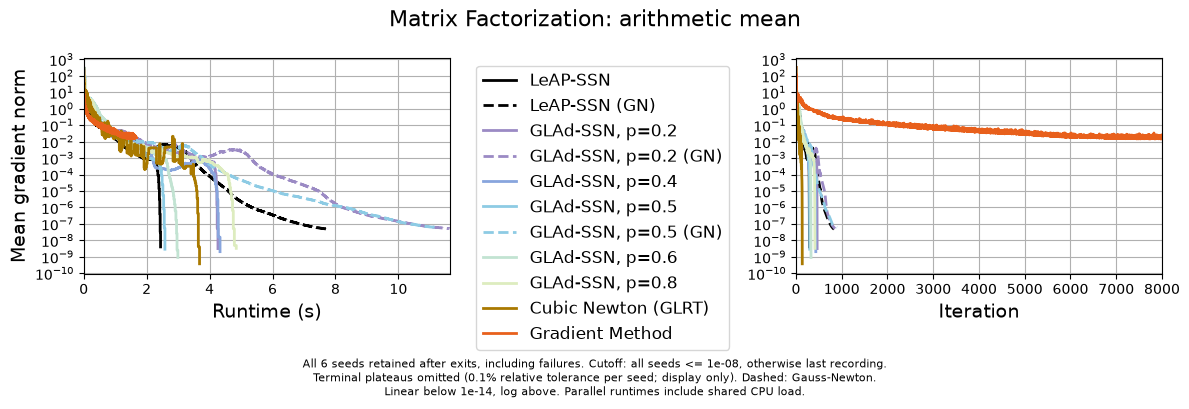

Plot cutoff: every seed's gradient norm <= 1e-08
runtime: target missed: LeAP-SSN (GN), GLAd-SSN, p=0.2 (GN), GLAd-SSN, p=0.5 (GN), Gradient Method
iteration: target missed: LeAP-SSN (GN), GLAd-SSN, p=0.2 (GN), GLAd-SSN, p=0.5 (GN), Gradient Method


In [46]:
from utils_new import prepare_mean_histories

if not batch_complete or set(all_seeds_histories) != set(seeds_to_try):
    raise RuntimeError("Complete the seed batch before computing the mean.")

# Same color for each exact/Gauss-Newton pair; dashed lines mark GN.
mean_gradient_base_colors = {
    name: method_colors[name] for name in ["LeAP-SSN"]
    + [f"GLAd-SSN, p={p:g}" for p in (0.2, 0.4, 0.5, 0.6, 0.8)]
}
mean_gradient_methods = {}
mean_gradient_missing = []
for base_name, color in mean_gradient_base_colors.items():
    for suffix in ("", " (GN)"):
        name = base_name + suffix
        if all(name in histories for histories in all_seeds_histories.values()):
            mean_gradient_methods[name] = color
        else:
            mean_gradient_missing.append(name)
mean_gradient_methods.update({"Cubic Newton (GLRT)": "#A97900", "Gradient Method": "#E8601C"})
mean_gradient_linestyles = {
    name: "--" if name.endswith(" (GN)") else "-" for name in mean_gradient_methods
}
if mean_gradient_missing:
    print("Not recorded for every seed:", ", ".join(mean_gradient_missing))
    print("For more GN pairs, include their p values in gn_exponents and rerun the seed batch.")
mean_gradient_target = run_metadata["configuration"]["grad_tol"]  # Display cutoff; solver unchanged.
mean_gradient_flat_tail_rtol = 1e-3  # Hide final plateaus within 0.1%; None disables.
mean_gradient_max_iter = None  # Full displayed range; e.g. 150 for a zoom.
mean_gradient_max_time = None  # Full displayed range; e.g. 200 for a zoom in seconds.

mean_objective_zero_scale = 1e-8  # Objective residual axis only.
mean_penalty_zero_scale = 1e-5  # Penalty axis only; preserve zeros and rebounds.

arithmetic_mean_histories = {}
arithmetic_mean_summaries = {}
for measure in ("func", "grad_norm", "penalty"):
    prepared, summary = prepare_mean_histories(
        all_seeds_histories, mean_gradient_methods, measure=measure,
        target=mean_gradient_target if measure == "grad_norm" else None,
        flat_tail_rtol=mean_gradient_flat_tail_rtol if measure == "grad_norm" else None,
    )
    arithmetic_mean_histories[measure] = prepared
    arithmetic_mean_summaries[measure] = summary

# One observed mean reference, shared by both objective panels and all methods.
mean_objective_reference = min(
    np.min(values) for summary in arithmetic_mean_summaries["func"].values()
    for values in summary["means"].values()
)
arithmetic_mean_figures = {}
for measure, reference, ylabel in [
    ("func", mean_objective_reference, "Mean objective residual"),
    ("grad_norm", 0, "Mean gradient norm"),
    ("penalty", 0, "Mean weighted penalty"),
]:
    prepared = arithmetic_mean_histories[measure]
    summary = arithmetic_mean_summaries[measure]
    limits = {}
    for axis, limit in [("runtime", mean_gradient_max_time), ("iteration", mean_gradient_max_iter)]:
        last_shown = max(e["x"] for e in summary[axis]["endpoints"].values())
        limits[axis] = limit if limit is not None else max(last_shown, 1e-12)
    scale = {"func": mean_objective_zero_scale, "grad_norm": 1e-14,
             "penalty": mean_penalty_zero_scale}[measure]
    note = f"All {len(all_seeds_histories)} seeds retained after exits, including failures. "
    if measure == "grad_norm":
        note += (f"Cutoff: all seeds <= {mean_gradient_target:g}, otherwise last recording."
                 if mean_gradient_target is not None else "Cutoff: each method's last recording.")
        if mean_gradient_flat_tail_rtol is not None:
            note += (f"\nTerminal plateaus omitted ({100 * mean_gradient_flat_tail_rtol:g}% relative tolerance "
                     "per seed; display only).")
    else:
        note += "Curves end at each method's last recording."
        if measure == "func":
            note += "\nReference: best observed mean across methods and both panels; not a known optimum."
    if any(style == "--" for style in mean_gradient_linestyles.values()):
        note += " Dashed: Gauss-Newton."
    note += f"\nLinear below {scale:g}, log above. Parallel runtimes include shared CPU load."
    fig = plot_figures(
        list(prepared.values()), list(mean_gradient_methods),
        colors=list(mean_gradient_methods.values()), linewidths=[2.0] * len(mean_gradient_methods),
        linestyles=[mean_gradient_linestyles[name] for name in mean_gradient_methods],
        n=n, m=m, mu_str=None, xlabel="Runtime (s)",
        f_star=reference, threshold=None, zero_scale=scale,
        max_time=limits["runtime"], max_iter=limits["iteration"],
        which_measure_1="runtime", which_measure_2="iteration", ylabel=ylabel,
        suptitle="Matrix Factorization: arithmetic mean",
        sharey=True, runtime_steps=True, verbose=False, note=note,
    )
    arithmetic_mean_figures[measure] = fig
    display(fig)
    plt.close(fig)

# Keep the existing gradient results available under their previous names.
mean_gradient_histories = arithmetic_mean_histories["grad_norm"]
mean_gradient_summaries = arithmetic_mean_summaries["grad_norm"]
mean_gradient_figure = arithmetic_mean_figures["grad_norm"]
if mean_gradient_target is not None:
    print(f"Plot cutoff: every seed's gradient norm <= {mean_gradient_target:g}")
    for axis, summary in mean_gradient_summaries.items():
        missed = [name for name, endpoint in summary["endpoints"].items()
                  if not endpoint["all_seeds_reached"]]
        if missed:
            print(f"{axis}: target missed:", ", ".join(missed))
for axis, summary in mean_gradient_summaries.items():
    trimmed = [name for name, endpoint in summary["endpoints"].items()
               if endpoint["flat_tail_trimmed"]]
    if trimmed:
        print(f"{axis}: terminal plateau hidden:", ", ".join(trimmed))

if SAVE_FIGURES:
    import json
    mean_output_dir = MF_DIR / "parallel_results" / ("arithmetic_mean_" + datetime.now().strftime("%Y%m%d_%H%M%S_%f"))
    mean_output_dir.mkdir(parents=True, exist_ok=False)
    for measure, filename in [("func", "mean_objective.pdf"), ("grad_norm", "mean_gradient.pdf"),
                              ("penalty", "mean_penalty.pdf")]:
        arithmetic_mean_figures[measure].savefig(mean_output_dir / filename, bbox_inches="tight")
    mean_record = dict(
        convention="All-seed arithmetic means with terminal values held; objective/penalty end at last recording, gradient additionally uses target/plateau cutoffs",
        objective_reference=float(mean_objective_reference),
        gradient_target=mean_gradient_target, gradient_flat_tail_rtol=mean_gradient_flat_tail_rtol,
        zero_scales=dict(func=mean_objective_zero_scale, grad_norm=1e-14, penalty=mean_penalty_zero_scale),
        seeds=list(seeds_to_try), methods=list(mean_gradient_methods),
        linestyles=mean_gradient_linestyles, missing_methods=mean_gradient_missing,
        max_iter=mean_gradient_max_iter, max_time=mean_gradient_max_time,
        run_metadata=run_metadata, statuses=all_seeds_statuses,
        summaries={measure: {
            axis: dict(grid=summary["grid"].tolist(), endpoints=summary["endpoints"],
                       means={name: values.tolist() for name, values in summary["means"].items()})
            for axis, summary in summaries.items()
        } for measure, summaries in arithmetic_mean_summaries.items()},
    )
    (mean_output_dir / "arithmetic_mean.json").write_text(
        json.dumps(mean_record, indent=2, allow_nan=False), encoding="utf-8")
    print("Saved arithmetic mean figures and data to", mean_output_dir)
